In [1]:
!wget -O LLCP2023XPT.zip https://www.cdc.gov/brfss/annual_data/2023/files/LLCP2023XPT.zip
!unzip -o LLCP2023XPT.zip -d data/
!mv "data/LLCP2023.XPT " data/LLCP2023.XPT
!rm LLCP2023XPT.zip
!ls data/


--2026-10-12 21:26:48--  https://www.cdc.gov/brfss/annual_data/2023/files/LLCP2023XPT.zip
Resolving www.cdc.gov (www.cdc.gov)... 2600:1416:3000:18c::2461, 2600:1416:3000:18d::2461, 23.50.198.86
Connecting to www.cdc.gov (www.cdc.gov)|2600:1416:3000:18c::2461|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 93237818 (89M) [application/x-zip-compressed]
Saving to: ‘LLCP2023XPT.zip’

LLCP2023XPT.zip     100%[===================>]  88.92M  6.61MB/s    in 13s     

2026-10-12 21:27:04 (6.65 MB/s) - ‘LLCP2023XPT.zip’ saved [93237818/93237818]

Archive:  LLCP2023XPT.zip
  inflating: data/LLCP2023.XPT       
diabete_study_test.csv	 diabete_study_val.csv
diabete_study_train.csv  LLCP2023.XPT


In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import (train_test_split, StratifiedShuffleSplit)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score,
                             roc_curve,
                             accuracy_score,
                             precision_score,
                             recall_score,
                             precision_recall_curve,
                             f1_score,
                             confusion_matrix
                             )

In [3]:
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [4]:
df = pd.read_sas("data/LLCP2023.XPT", format="xport", encoding="latin-1")
df.head()

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,03012023,03,01,2023,1100.0,2023000001,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1.0,1.0,01062023,01,06,2023,1100.0,2023000002,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
2,1.0,1.0,03082023,03,08,2023,1100.0,2023000003,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,03062023,03,06,2023,1100.0,2023000004,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,1.0,1.0,1.0,9.0
4,1.0,1.0,01062023,01,06,2023,1100.0,2023000005,2.023000e+09,1.0,...,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,2.0,1.0,1.0,2.0


In [5]:
target = "DIABETE4"

binary_cols = ["_RFHYPE6", "_RFCHOL3", "CVDSTRK3", "_MICHD", "CHCKDNY2",
               "_TOTINDA", "_RFDRHV8", "_HLTHPL1", "MEDCOST1", "DIFFWALK", "_SEX"]
ordinal_cols = ["GENHLTH", "_AGEG5YR", "_EDUCAG", "_INCOMG1", "_SMOKER3", "_CHOLCH3"]
numeric_cols = ["_BMI5", "PHYSHLTH", "MENTHLTH", "_DRNKWK2", "DROCDY4_",
                "_AGE80", "HTIN4", "WTKG3", "PA3MIN_", "PA3VIGM_", "STRFREQ_"]

In [6]:
diabete_study = df[numeric_cols + ordinal_cols + binary_cols + [target]]
diabete_study.to_csv("BRFSS_dataset.csv", index=False)

In [7]:
data = pd.read_csv("BRFSS_dataset.csv")
data.shape

(433323, 29)

In [8]:
data.columns

Index(['_BMI5', 'PHYSHLTH', 'MENTHLTH', '_DRNKWK2', 'DROCDY4_', '_AGE80',
       'HTIN4', 'WTKG3', 'PA3MIN_', 'PA3VIGM_', 'STRFREQ_', 'GENHLTH',
       '_AGEG5YR', '_EDUCAG', '_INCOMG1', '_SMOKER3', '_CHOLCH3', '_RFHYPE6',
       '_RFCHOL3', 'CVDSTRK3', '_MICHD', 'CHCKDNY2', '_TOTINDA', '_RFDRHV8',
       '_HLTHPL1', 'MEDCOST1', 'DIFFWALK', '_SEX', 'DIABETE4'],
      dtype='object')

In [9]:
# rename columns from code to variable names
column_names = {
    # Target
    "DIABETE4": "diabetes",

    # Binary
    "_RFHYPE6": "high_blood_pressure",
    "_RFCHOL3": "high_cholesterol",
    "CVDSTRK3": "stroke",
    "_MICHD":   "heart_disease",
    "CHCKDNY2": "kidney_disease",
    "_TOTINDA": "physical_activity",
    "_RFDRHV8": "heavy_drinker",
    "_HLTHPL1": "health_insurance",
    "MEDCOST1": "cant_afford_doctor",
    "DIFFWALK": "difficulty_walking",
    "_SEX":     "sex",

    # Ordinal
    "GENHLTH":  "general_health",
    "_AGEG5YR": "age_group",
    "_EDUCAG":  "education",
    "_INCOMG1": "income",
    "_SMOKER3": "smoking_status",
    "_CHOLCH3": "cholesterol_check",

    # Numeric
    "_BMI5":    "bmi",
    "PHYSHLTH": "poor_physical_health_days",
    "MENTHLTH": "poor_mental_health_days",
    "_DRNKWK2": "drinks_per_week",
    "DROCDY4_": "drink_occasions_per_day",
    "_AGE80":   "age",
    "HTIN4":    "height_inches",
    "WTKG3":     "weight_kg",
    "PA3MIN_":  "exercise_minutes_per_week",
    "PA3VIGM_": "vigorous_exercise_minutes_per_week",
    "STRFREQ_": "strength_training_per_week",
}

data_renamed = data.rename(columns=column_names)


In [10]:
num = data_renamed.select_dtypes("number").columns
data_renamed[num] = data_renamed[num].mask(data_renamed[num].abs() < 1e-10, 0)

In [11]:
data_renamed.head()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
0,3047.0,88.0,88.0,0.0,0.0,80.0,63.0,7802.0,NaN,NaN,...,2.0,2.0,2.0,2.0,1.0,1.0,2.0,1.0,2.0,1.0
1,2856.0,88.0,88.0,0.0,0.0,80.0,57.0,5987.0,360.0,180.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,2.0,2.0,3.0
2,2231.0,6.0,2.0,0.0,0.0,80.0,64.0,5897.0,36.0,18.0,...,2.0,2.0,2.0,1.0,1.0,1.0,1.0,1.0,2.0,3.0
3,2744.0,2.0,88.0,0.0,0.0,78.0,66.0,7711.0,180.0,90.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,3.0
4,2585.0,88.0,88.0,47.0,7.0,76.0,68.0,7711.0,600.0,90.0,...,2.0,2.0,2.0,1.0,1.0,1.0,2.0,1.0,2.0,1.0


## Basic Data Explaratory and handling missing values
The BRFSS survey is an encoded survey where numbers 7 and 9 mean respectfully don't know or refused to provide. In this study, we will consider it as NaN value. Let's first check how many of them are there per columns. These two codes are included in following features: **["diabetes", "stroke", "kidney_disease", "cant_afford_doctor", "difficulty_walking", "general_health"]**
Reference source: **codebook23_llcp-v2-508**

In [12]:
## check for missingness
dk_cols = ["diabetes", "stroke", "kidney_disease", "cant_afford_doctor",
           "difficulty_walking", "general_health", "difficulty_walking",
           "high_cholesterol"]

missing_table = pd.DataFrame({
    "7 appearance in %":     (data_renamed[dk_cols] == 7).mean() * 100,
    "9 appearance in %":     (data_renamed[dk_cols] == 9).mean() * 100,
    "7 & 9 appearance in %": data_renamed[dk_cols].isin([7, 9]).mean() * 100,
}).round(2)
missing_table.index.name = "column_name"

missing_table


,7 appearance in %,9 appearance in %,7 & 9 appearance in %
column_name,,,
diabetes,0.16,0.07,0.23
stroke,0.28,0.06,0.34
kidney_disease,0.37,0.06,0.44
cant_afford_doctor,0.27,0.08,0.35
difficulty_walking,0.28,0.11,0.39
general_health,0.21,0.08,0.29
difficulty_walking,0.28,0.11,0.39
high_cholesterol,0.00,0.76,0.76


In [13]:
## check for NAN
columns = ["exercise_minutes_per_week",
           "vigorous_exercise_minutes_per_week",
           "high_cholesterol","bmi","weight_kg",
           "height_inches","strength_training_per_week",
           "heart_disease"

           ]

In [14]:
# Codes that mean "don't know / refused / missing" in each column
missing_codes = {
    "diabetes":                   [7, 9],
    "stroke":                     [7, 9],
    "kidney_disease":             [7, 9],
    "cant_afford_doctor":         [7, 9],
    "difficulty_walking":         [7, 9],
    "general_health":             [7, 9],
    "high_blood_pressure":        [9],
    "high_cholesterol":           [9],
    "physical_activity":          [9],
    "heavy_drinker":              [9],
    "health_insurance":           [9],
    "education":                  [9],
    "income":                     [9],
    "smoking_status":             [9],
    "cholesterol_check":          [9],
    "poor_physical_health_days":  [77, 99],
    "poor_mental_health_days":    [77, 99],
    "age_group":                  [14],
    "drinks_per_week":            [99900],
    "drink_occasions_per_day":    [900],
    "strength_training_per_week": [99000],
}

all_codes = [7, 9, 77, 99, 14, 99900, 900, 99000]

rows = {}
for col, codes in missing_codes.items():
    s = data_renamed[col]
    row = {f"{c} appearance in %": (s == c).mean() * 100 if c in codes else np.nan
           for c in all_codes}
    row["NaN in %"] = s.isna().mean() * 100
    row["total missing in %"] = (s.isin(codes) | s.isna()).mean() * 100
    rows[col] = row

missing_table = pd.DataFrame(rows).T.round(2)
missing_table.index.name = "column_name"

missing_table.sort_values("total missing in %", ascending=False)


,7 appearance in %,9 appearance in %,77 appearance in %,99 appearance in %,14 appearance in %,99900 appearance in %,900 appearance in %,99000 appearance in %,NaN in %,total missing in %
column_name,,,,,,,,,,
income,NaN,19.99,NaN,NaN,NaN,NaN,NaN,NaN,0.00,19.99
high_cholesterol,NaN,0.76,NaN,NaN,NaN,NaN,NaN,NaN,11.96,12.71
heavy_drinker,NaN,7.58,NaN,NaN,NaN,NaN,NaN,NaN,0.00,7.58
drinks_per_week,NaN,NaN,NaN,NaN,NaN,7.58,NaN,NaN,0.00,7.58
drink_occasions_per_day,NaN,NaN,NaN,NaN,NaN,NaN,6.91,NaN,0.00,6.91
cholesterol_check,NaN,6.10,NaN,NaN,NaN,NaN,NaN,NaN,0.00,6.10
smoking_status,NaN,5.32,NaN,NaN,NaN,NaN,NaN,NaN,0.00,5.32
health_insurance,NaN,4.31,NaN,NaN,NaN,NaN,NaN,NaN,0.00,4.31
difficulty_walking,0.28,0.11,NaN,NaN,NaN,NaN,NaN,NaN,3.73,4.12


Drop 7 and 9 inside the target (7=don't know, 9=refused)

In [15]:
data_renamed["diabetes"].value_counts()

diabetes
3.0    358706
1.0     59786
4.0     10594
2.0      3253
7.0       683
9.0       296
Name: count, dtype: int64

In [16]:
# Drop rows where the target is unknown (7 = don't know, 9 = refused) or blank
clean_data = data_renamed[~data_renamed["diabetes"].isin([7, 9])]
clean_data = clean_data.dropna(subset=["diabetes"])

print(f"{len(data_renamed)} rows before 'vs', {len(clean_data)} rows now")
clean_data["diabetes"].value_counts()


433323 rows before 'vs', 432339 rows now


diabetes
3.0    358706
1.0     59786
4.0     10594
2.0      3253
Name: count, dtype: int64

In [17]:
## replace 7 (don't know) with NaN
columns = ["difficulty_walking", "kidney_disease", "cant_afford_doctor",
           "stroke", "general_health"]
clean_data[columns].head()

,difficulty_walking,kidney_disease,cant_afford_doctor,stroke,general_health
0,1.0,2.0,2.0,2.0,2.0
1,2.0,2.0,2.0,2.0,2.0
2,1.0,2.0,1.0,2.0,4.0
3,1.0,2.0,2.0,2.0,2.0
4,1.0,2.0,2.0,2.0,4.0


In [18]:
clean_data["high_cholesterol"] = clean_data["high_cholesterol"].fillna(-1)   # -1 = unknown


In [19]:
# Codes that mean "don't know / refused / missing" in each column
to_nan = {
    "stroke":                     [7, 9],
    "kidney_disease":             [7, 9],
    "cant_afford_doctor":         [7, 9],
    "difficulty_walking":         [7, 9],
    "general_health":             [7, 9],
    "high_blood_pressure":        [9],
    "physical_activity":          [9],
    "heavy_drinker":              [9],
    "health_insurance":           [9],
    "education":                  [9],
    "smoking_status":             [9],
    "cholesterol_check":          [9],
    "poor_physical_health_days":  [77, 99],
    "poor_mental_health_days":    [77, 99],
    "age_group":                  [14],
    "drinks_per_week":            [99900],
    "drink_occasions_per_day":    [900],
    "strength_training_per_week": [99000],
}

clean_data = clean_data.replace({col: {code: np.nan for code in codes}
                                 for col, codes in to_nan.items()})


In [20]:
for col in ["poor_physical_health_days", "poor_mental_health_days"]:
    clean_data[col] = clean_data[col].replace(88, 0)

In [21]:
# check for missing values
(clean_data.isna().mean() * 100).round(2).sort_values(ascending=False)

exercise_minutes_per_week             28.38
vigorous_exercise_minutes_per_week    27.34
bmi                                    9.30
weight_kg                              7.83
drinks_per_week                        7.54
heavy_drinker                          7.54
drink_occasions_per_day                6.88
height_inches                          6.42
cholesterol_check                      6.06
smoking_status                         5.29
health_insurance                       4.27
difficulty_walking                     4.09
strength_training_per_week             3.29
poor_physical_health_days              2.47
poor_mental_health_days                1.85
age_group                              1.75
heart_disease                          1.00
education                              0.51
high_blood_pressure                    0.40
kidney_disease                         0.37
cant_afford_doctor                     0.34
stroke                                 0.28
general_health                  

In [22]:
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 432339 entries, 0 to 433322
Data columns (total 29 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   bmi                                 392119 non-null  float64
 1   poor_physical_health_days           421667 non-null  float64
 2   poor_mental_health_days             424355 non-null  float64
 3   drinks_per_week                     399739 non-null  float64
 4   drink_occasions_per_day             402612 non-null  float64
 5   age                                 432339 non-null  float64
 6   height_inches                       404602 non-null  float64
 7   weight_kg                           398482 non-null  float64
 8   exercise_minutes_per_week           309628 non-null  float64
 9   vigorous_exercise_minutes_per_week  314131 non-null  float64
 10  strength_training_per_week          418108 non-null  float64
 11  general_health                 

In [23]:
clean_data.describe()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
count,392119.000000,421667.000000,424355.000000,399739.000000,402612.000000,432339.000000,404602.000000,398482.000000,309628.000000,314131.000000,...,431119.000000,428022.000000,430728.000000,431143.000000,399739.000000,413881.000000,430870.000000,414666.000000,432339.000000,432339.000000
mean,2847.766461,4.478899,4.355040,280.333270,16.430516,55.379346,67.066945,8288.308315,636.715375,162.025047,...,1.957555,1.915378,1.952367,1.247115,1.059249,1.054591,1.914125,1.838916,1.529837,2.740410
std,653.954620,8.823183,8.316287,815.396316,27.138132,17.909326,4.185244,2133.152545,1323.048113,536.396921,...,0.201603,0.278318,0.212989,0.431335,0.236090,0.227180,0.280180,0.367609,0.499110,0.719571
min,1202.000000,0.000000,0.000000,0.000000,0.000000,18.000000,36.000000,2268.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,2410.000000,0.000000,0.000000,0.000000,0.000000,41.000000,64.000000,6804.000000,140.000000,0.000000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,1.000000,3.000000
50%,2740.000000,0.000000,0.000000,23.000000,3.000000,58.000000,67.000000,8029.000000,315.000000,0.000000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,3.000000
75%,3162.000000,4.000000,5.000000,233.000000,17.000000,71.000000,70.000000,9435.000000,672.000000,144.500000,...,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,3.000000
max,9984.000000,30.000000,30.000000,53200.000000,100.000000,80.000000,95.000000,28400.000000,118602.000000,59301.000000,...,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,4.000000


Features/target

In [24]:
TARGET = "diabetes"
features = [
    # Numeric
    "bmi", "poor_physical_health_days", "poor_mental_health_days",
    "drinks_per_week", "drink_occasions_per_day", "age",
    "height_inches", "weight_kg", "exercise_minutes_per_week",
    "vigorous_exercise_minutes_per_week", "strength_training_per_week",

    # Ordinal
    "general_health", "age_group", "education", "income",
    "smoking_status", "cholesterol_check",

    # Binary
    "high_blood_pressure", "high_cholesterol", "stroke", "heart_disease",
    "kidney_disease", "physical_activity", "heavy_drinker",
    "health_insurance", "cant_afford_doctor", "difficulty_walking", "sex",
]

## Encode Binaries values
for sex, 0 is male and 1 is female

In [25]:
# 1 i yes, 2 is no
one_is_yes = ["stroke", "heart_disease", "kidney_disease", "cant_afford_doctor",
              "difficulty_walking", "physical_activity", "health_insurance"]

# 1 is no, 2 is yes
one_is_no = ["high_blood_pressure", "high_cholesterol", "heavy_drinker"]


In [26]:
for col in one_is_yes:
    clean_data[col] = clean_data[col].map({1: 1, 2: 0})

for col in one_is_no:
    clean_data[col] = clean_data[col].map({1: 0, 2: 1})

clean_data["sex"] = clean_data["sex"].map({1: 0, 2: 1})


## Encode ordinal values

In [27]:
# smoking: 0 = never, 1 = former, 2 = some days, 3 = daily
clean_data["smoking_status"] = clean_data["smoking_status"].map({4: 0, 3: 1, 2: 2, 1: 3})

# cholesterol check: 0 = within 5 years, 1 = more than 5 years ago, 2 = never
clean_data["cholesterol_check"] = clean_data["cholesterol_check"].map({1: 0, 2: 1, 3: 2})

# income: keep 1–7, unknown (9) becomes 0
clean_data["income"] = clean_data["income"].replace(9, 0)

# age group: 0 = 18–24, 1 = 25–29, ..., 12 = 80+
clean_data["age_group"] = clean_data["age_group"] - 1


BRFSS for privacy reasons multiplied some numerical values to 100 or 1000. This section will bring those features to their initial values

In [28]:
scale_map = {
    "bmi": 100,
    "weight_kg": 100,
    "drinks_per_week": 100,
    "drink_occasions_per_day": 100,
    "strength_training_per_week": 1000,
}
for col, factor in scale_map.items():
    clean_data[col] = clean_data[col] / factor
print("Complete")

Complete


In [29]:
clean_data.head()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
0,30.47,0.0,0.0,0.00,0.00,80.0,63.0,78.02,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1,1.0
1,28.56,0.0,0.0,0.00,0.00,80.0,57.0,59.87,360.0,180.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1,3.0
2,22.31,6.0,2.0,0.00,0.00,80.0,64.0,58.97,36.0,18.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,1.0,1,3.0
3,27.44,2.0,0.0,0.00,0.00,78.0,66.0,77.11,180.0,90.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1,3.0
4,25.85,0.0,0.0,0.47,0.07,76.0,68.0,77.11,600.0,90.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1,1.0


In [30]:
clean_data["high_cholesterol"].value_counts()

high_cholesterol
0.0    219032
1.0    158647
Name: count, dtype: int64

## Check for outlier

In [31]:
clean_data.describe()

,bmi,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,age,height_inches,weight_kg,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,...,stroke,heart_disease,kidney_disease,physical_activity,heavy_drinker,health_insurance,cant_afford_doctor,difficulty_walking,sex,diabetes
count,392119.000000,421667.000000,424355.000000,399739.000000,402612.000000,432339.000000,404602.000000,398482.000000,309628.000000,314131.000000,...,431119.000000,428022.000000,430728.000000,431143.000000,399739.000000,413881.000000,430870.000000,414666.000000,432339.000000,432339.000000
mean,28.477665,4.478899,4.355040,2.803333,0.164305,55.379346,67.066945,82.883083,636.715375,162.025047,...,0.042445,0.084622,0.047633,0.752885,0.059249,0.945409,0.085875,0.161084,0.529837,2.740410
std,6.539546,8.823183,8.316287,8.153963,0.271381,17.909326,4.185244,21.331525,1323.048113,536.396921,...,0.201603,0.278318,0.212989,0.431335,0.236090,0.227180,0.280180,0.367609,0.499110,0.719571
min,12.020000,0.000000,0.000000,0.000000,0.000000,18.000000,36.000000,22.680000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,24.100000,0.000000,0.000000,0.000000,0.000000,41.000000,64.000000,68.040000,140.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,3.000000
50%,27.400000,0.000000,0.000000,0.230000,0.030000,58.000000,67.000000,80.290000,315.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,3.000000
75%,31.620000,4.000000,5.000000,2.330000,0.170000,71.000000,70.000000,94.350000,672.000000,144.500000,...,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,3.000000
max,99.840000,30.000000,30.000000,532.000000,1.000000,80.000000,95.000000,284.000000,118602.000000,59301.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,4.000000


drinks_per_week shows a surprising maximun value of 532 drinks in a week, which is in average around 76 drinks per day.

In [32]:
# check the distribution of drinks_per_week
clean_data["drinks_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])


0.25000      0.000000
0.50000      0.230000
0.75000      2.330000
0.90000      8.000000
0.95000     14.000000
0.99000     30.000000
0.99900     84.000000
0.99990    224.244446
0.99999    511.036680
1.00000    532.000000
Name: drinks_per_week, dtype: float64

At 99.9% quantile, only 84 drinks were taken in a week, which is 12 drinks per day.  At 99.99%, it is 224 drinks per week, around 32 drinks per day. According to the Ohio State report, a clinical sample of people with alcohol use disorder averaged 6.4 drinks per day. My personal assumption is that values in the extreme outliers might be due to a typing error. The value will be capped at 0.999 quantile

In [33]:
cap = clean_data["drinks_per_week"].quantile(0.999)
clean_data["drinks_per_week"] = clean_data["drinks_per_week"].clip(upper=cap)


**exercise_minutes_per_week and vigorous_exercise_minutes_per_week also have an issue. Their maximun values are 118602 and 59301 minutes while a week has 24*60*7 minutes = 10080 minutes**

In [34]:
check_activity_min = clean_data["exercise_minutes_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])
hourly_check_weekly = {
    "quantile %": check_activity_min.index * 100,
    "minutes": check_activity_min,
    "hours":check_activity_min/60
    }
pd.DataFrame(hourly_check_weekly)

,quantile %,minutes,hours
0.25000,25.000,140.0000,2.333333
0.50000,50.000,315.0000,5.250000
0.75000,75.000,672.0000,11.200000
0.90000,90.000,1440.0000,24.000000
0.95000,95.000,2310.0000,38.500000
0.99000,99.000,4872.0000,81.200000
0.99900,99.900,13244.7600,220.746000
0.99990,99.990,47522.2380,792.037300
0.99999,99.999,94416.1704,1573.602840
1.00000,100.000,118602.0000,1976.700000


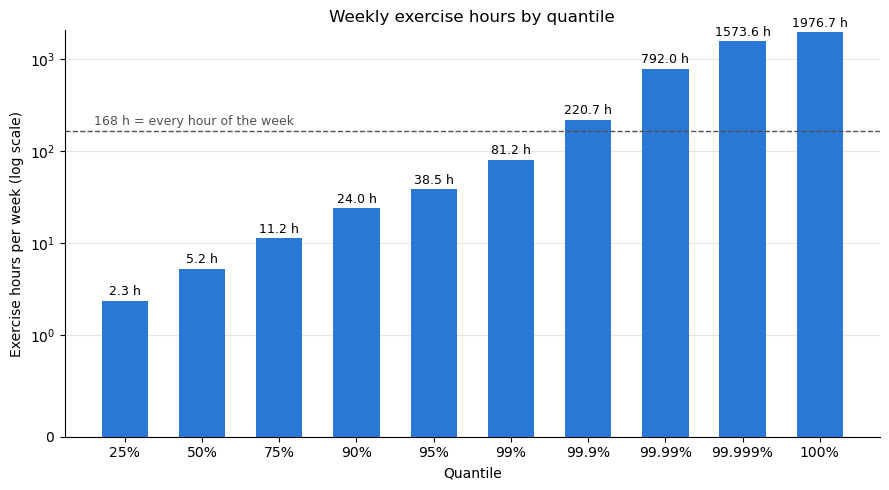

In [35]:
import matplotlib.pyplot as plt
hourly_df = pd.DataFrame(hourly_check_weekly)

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"{q:g}%" for q in hourly_df["quantile %"]]
bars = ax.bar(labels, hourly_df["hours"], color="#2a78d6", width=0.6)

# Value on top of each bar
for bar, h in zip(bars, hourly_df["hours"]):
    ax.annotate(f"{h:.1f} h", (bar.get_x() + bar.get_width() / 2, h),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

# A week has 168 hours: anything above this line is impossible
ax.axhline(168, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.4, 168 * 1.15, "168 h = every hour of the week", color="#52514e", fontsize=9)

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Quantile")
ax.set_ylabel("Exercise hours per week (log scale)")
ax.set_title("Weekly exercise hours by quantile")
ax.grid(axis="y", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


Considering that a week has 168h (24h per day), any practice value beyond 168h is mathematically impossible. At 99%, a consistent practice time of 81.2h per week (11h per day) seems also to be quite impossible even for profesionnal athletes. The most plausible value is found at 95% quantile (38.5h)

In [36]:
cap = clean_data["exercise_minutes_per_week"].quantile(0.95)
clean_data["exercise_minutes_per_week"] = clean_data["exercise_minutes_per_week"].clip(upper=cap)

Check for vigorous_exercise_minutes_per_week

In [37]:
check_activity_min = clean_data["vigorous_exercise_minutes_per_week"].quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999, 0.9999, 0.99999, 1.0])
hourly_check_weekly = {
    "quantile %": check_activity_min.index * 100,
    "minutes": check_activity_min,
    "hours":check_activity_min/60
    }
pd.DataFrame(hourly_check_weekly)

,quantile %,minutes,hours
0.25000,25.000,0.000,0.000000
0.50000,50.000,0.000,0.000000
0.75000,75.000,144.500,2.408333
0.90000,90.000,420.000,7.000000
0.95000,95.000,780.000,13.000000
0.99000,99.000,2100.000,35.000000
0.99900,99.900,4620.000,77.000000
0.99990,99.990,16051.320,267.522000
0.99999,99.999,43364.376,722.739600
1.00000,100.000,59301.000,988.350000


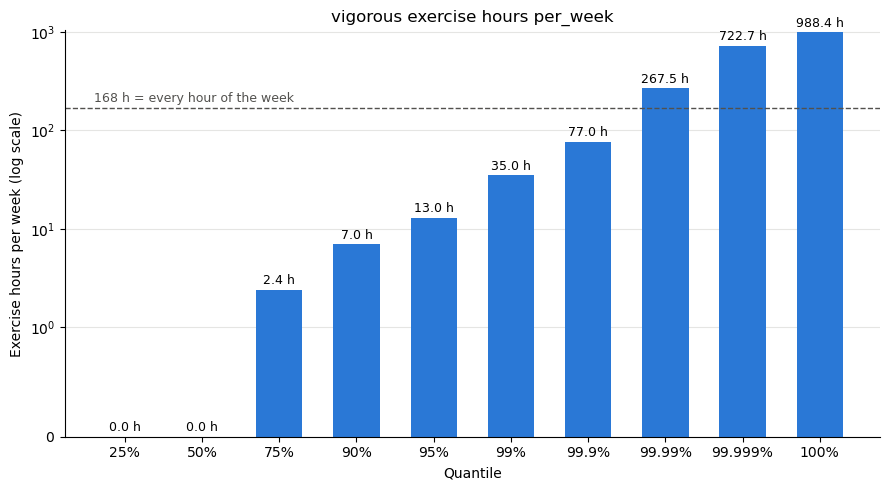

In [38]:
hourly_df = pd.DataFrame(hourly_check_weekly)

fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"{q:g}%" for q in hourly_df["quantile %"]]
bars = ax.bar(labels, hourly_df["hours"], color="#2a78d6", width=0.6)

# Value on top of each bar
for bar, h in zip(bars, hourly_df["hours"]):
    ax.annotate(f"{h:.1f} h", (bar.get_x() + bar.get_width() / 2, h),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)

# A week has 168 hours: anything above this line is impossible
ax.axhline(168, color="#52514e", linewidth=1, linestyle="--")
ax.text(-0.4, 168 * 1.15, "168 h = every hour of the week", color="#52514e", fontsize=9)

ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("Quantile")
ax.set_ylabel("Exercise hours per week (log scale)")
ax.set_title("vigorous exercise hours per_week")
ax.grid(axis="y", color="#e5e5e3", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


In [39]:
cap = clean_data["vigorous_exercise_minutes_per_week"].quantile(0.95)
clean_data["vigorous_exercise_minutes_per_week"] = clean_data["vigorous_exercise_minutes_per_week"].clip(upper=cap)

In [40]:
numeric_cols = ["bmi", "age", "height_inches", "weight_kg",
                "poor_physical_health_days", "poor_mental_health_days",
                "drinks_per_week", "drink_occasions_per_day",
                "exercise_minutes_per_week", "vigorous_exercise_minutes_per_week",
                "strength_training_per_week"]

clean_data[numeric_cols].describe()

,bmi,age,height_inches,weight_kg,poor_physical_health_days,poor_mental_health_days,drinks_per_week,drink_occasions_per_day,exercise_minutes_per_week,vigorous_exercise_minutes_per_week,strength_training_per_week
count,392119.000000,432339.000000,404602.000000,398482.000000,421667.000000,424355.000000,399739.000000,402612.000000,309628.000000,314131.000000,418108.000000
mean,28.477665,55.379346,67.066945,82.883083,4.478899,4.355040,2.738830,0.164305,539.627020,118.849458,1.863999
std,6.539546,17.909326,4.185244,21.331525,8.823183,8.316287,6.682283,0.271381,596.439761,212.596378,2.844207
min,12.020000,18.000000,36.000000,22.680000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24.100000,41.000000,64.000000,68.040000,0.000000,0.000000,0.000000,0.000000,140.000000,0.000000,0.000000
50%,27.400000,58.000000,67.000000,80.290000,0.000000,0.000000,0.230000,0.030000,315.000000,0.000000,0.467000
75%,31.620000,71.000000,70.000000,94.350000,4.000000,5.000000,2.330000,0.170000,672.000000,144.500000,3.000000
max,99.840000,80.000000,95.000000,284.000000,30.000000,30.000000,84.000000,1.000000,2310.000000,780.000000,97.000000


Similar with exercise per week, any value above the total number of hours per week (168h) is impossible and 11h constant exercise is not very plausible. We will also cap at 95% quantille.

At 99%, it is recorded at 4872 min, which is equivalent to 81.2h per week, 

In [41]:
X = clean_data[features]
Y = clean_data[TARGET]

Check for class Imbalance

In [42]:
classes = Y.value_counts()
target_class_imbalance = pd.DataFrame({
    "class": classes.index,
    "class_percentage %": (classes * 100 / len(Y)).round(2),
}).reset_index(drop=True)
target_class_imbalance

,class,class_percentage %
0,3.0,82.97
1,1.0,13.83
2,4.0,2.45
3,2.0,0.75


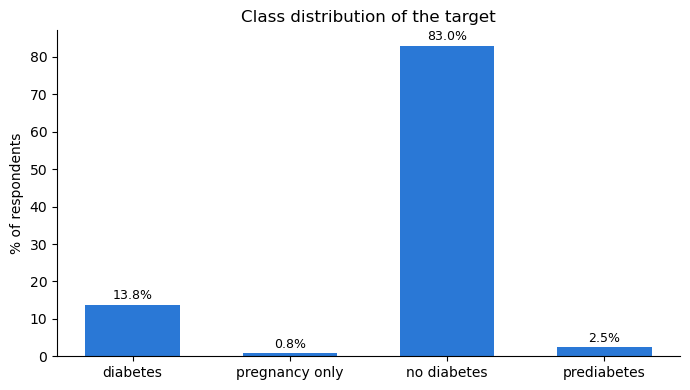

In [43]:
classes = Y.value_counts().sort_index()
target_class_imbalance = pd.DataFrame({
    "class": classes.index.astype(int).astype(str),
    "class_percentage": (classes / len(Y) * 100).round(2).values,
})

class_names = {"1": "diabetes", "2": "pregnancy only", "3": "no diabetes", "4": "prediabetes"}
labels = target_class_imbalance["class"].map(class_names)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, target_class_imbalance["class_percentage"], color="#2a78d6", width=0.6)
for bar, p in zip(bars, target_class_imbalance["class_percentage"]):
    ax.annotate(f"{p:.1f}%", (bar.get_x() + bar.get_width() / 2, p),
                textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)
ax.set_ylabel("% of respondents")
ax.set_title("Class distribution of the target")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()


In [44]:
import os
from datetime import datetime
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (roc_auc_score,
                             roc_curve,
                             accuracy_score,
                             balanced_accuracy_score,
                             precision_score,
                             recall_score,
                             precision_recall_curve,
                             f1_score,
                             confusion_matrix,
                             classification_report)
from tensorboardX import SummaryWriter

RANDOM_STATE = 42
LOG_DIR = "runs"   # view with: tensorboard --logdir runs
CLASS_NAMES = {1: "diabetes", 2: "pregnancy only", 3: "no diabetes", 4: "prediabetes"}
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
results_log = []   # every experiment's summary lands here -> becomes your results table


def log_experiment(run_name, pipeline, config, X_train, y_train, X_val, y_val,
                   do_cv=True,use_tensorboard=True):
    '''
    Fits `pipeline`, evaluates it on the validation set, logs to TensorBoard,
    and records a row for the results table. Returns the fitted pipeline.

    run_name : short descriptive string, e.g. "logreg_balanced"
    config   : dict of whatever you want tracked, e.g. {"model": "LogisticRegression", "C": 1.0}
    '''
    pipeline.fit(X_train, y_train)
    classes = pipeline.classes_
    labels = [CLASS_NAMES.get(int(c), str(c)) for c in classes]

    val_probs = pipeline.predict_proba(X_val)
    val_preds = pipeline.predict(X_val)
    y_val_bin = label_binarize(y_val, classes=classes)

    # ---------- Overall metrics ----------
    metrics = {
        "val_accuracy": accuracy_score(y_val, val_preds),
        "val_balanced_accuracy": balanced_accuracy_score(y_val, val_preds),
        "val_precision_macro": precision_score(y_val, val_preds, average="macro", zero_division=0),
        "val_recall_macro": recall_score(y_val, val_preds, average="macro", zero_division=0),
        "val_f1_macro": f1_score(y_val, val_preds, average="macro", zero_division=0),
        "val_precision_weighted": precision_score(y_val, val_preds, average="weighted", zero_division=0),
        "val_recall_weighted": recall_score(y_val, val_preds, average="weighted", zero_division=0),
        "val_f1_weighted": f1_score(y_val, val_preds, average="weighted", zero_division=0),
        "val_roc_auc_ovr": roc_auc_score(y_val, val_probs, multi_class="ovr", average="macro"),
    }

    # ---------- Per-class metrics ----------
    per_class_precision = precision_score(y_val, val_preds, average=None, labels=classes, zero_division=0)
    per_class_recall = recall_score(y_val, val_preds, average=None, labels=classes, zero_division=0)
    per_class_f1 = f1_score(y_val, val_preds, average=None, labels=classes, zero_division=0)
    for k, name in enumerate(labels):
        metrics[f"val_precision/{name}"] = per_class_precision[k]
        metrics[f"val_recall/{name}"] = per_class_recall[k]
        metrics[f"val_f1/{name}"] = per_class_f1[k]
        metrics[f"val_roc_auc/{name}"] = roc_auc_score(y_val_bin[:, k], val_probs[:, k])

    # ---------- Cross-validation on the TRAINING data only ----------
    if do_cv:
        cv_scoring = {
            "accuracy": "accuracy",
            "balanced_accuracy": "balanced_accuracy",
            "precision_macro": "precision_macro",
            "recall_macro": "recall_macro",
            "f1_macro": "f1_macro",
            "roc_auc_ovr": "roc_auc_ovr",
        }
        cv = cross_validate(
            pipeline, X_train, y_train,
            cv=StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE),
            scoring=cv_scoring,
            n_jobs=-1,
        )
        for name in cv_scoring:
            metrics[f"cv_{name}_mean"] = cv[f"test_{name}"].mean()
            metrics[f"cv_{name}_std"] = cv[f"test_{name}"].std()

    print(f"[{run_name}] accuracy = {metrics['val_accuracy']:.4f} | "
          f"balanced acc = {metrics['val_balanced_accuracy']:.4f} | "
          f"macro precision = {metrics['val_precision_macro']:.4f} | "
          f"macro recall = {metrics['val_recall_macro']:.4f} | "
          f"macro F1 = {metrics['val_f1_macro']:.4f} | "
          f"ROC-AUC (OvR) = {metrics['val_roc_auc_ovr']:.4f}"
          + (f"\n    CV macro F1 = {metrics['cv_f1_macro_mean']:.4f} (+/- {metrics['cv_f1_macro_std']:.4f}) | "
             f"CV ROC-AUC = {metrics['cv_roc_auc_ovr_mean']:.4f} (+/- {metrics['cv_roc_auc_ovr_std']:.4f})"
             if do_cv else ""))
    print(classification_report(y_val, val_preds, labels=classes, target_names=labels,
                                digits=3, zero_division=0))

    # ---------- Confusion matrix, normalized by row (= recall per class) ----------
    cm = confusion_matrix(y_val, val_preds, labels=classes, normalize="true")
    fig_cm, ax = plt.subplots(figsize=(5.5, 5))
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center",
                    color="white" if cm[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(classes)), labels, rotation=30, ha="right")
    ax.set_yticks(range(len(classes)), labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(run_name)
    fig_cm.tight_layout()

    # ---------- ROC and precision-recall curves (one-vs-rest, one curve per class) ----------
    fig_curves, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(11, 4.5))
    for k, (name, color) in enumerate(zip(labels, CLASS_COLORS)):
        fpr, tpr, _ = roc_curve(y_val_bin[:, k], val_probs[:, k])
        ax_roc.plot(fpr, tpr, color=color, linewidth=2,
                    label=f"{name} (AUC={metrics[f'val_roc_auc/{name}']:.2f})")

        prec, rec, _ = precision_recall_curve(y_val_bin[:, k], val_probs[:, k])
        ax_pr.plot(rec, prec, color=color, linewidth=2, label=name)
        ax_pr.axhline(y_val_bin[:, k].mean(), color=color, linewidth=1, linestyle=":")  # random-guess level

    ax_roc.plot([0, 1], [0, 1], color="#52514e", linewidth=1, linestyle="--")
    ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC (one-vs-rest)")
    ax_pr.set(xlabel="Recall", ylabel="Precision", title="Precision-recall (one-vs-rest)")
    for a in (ax_roc, ax_pr):
        a.legend(fontsize=8)
        for side in ["top", "right"]:
            a.spines[side].set_visible(False)
    fig_curves.suptitle(run_name)
    fig_curves.tight_layout()

    # ---------- TensorBoard ----------
    if use_tensorboard:
        try:
            stamp = datetime.now().strftime("%Y%m%d-%H%M%S")
            writer = SummaryWriter(os.path.join(LOG_DIR, f"{run_name}_{stamp}"))
            for k, v in metrics.items():
                writer.add_scalar(k, v, 0)
            writer.add_figure("confusion_matrix", fig_cm, 0, close=False)
            writer.add_figure("roc_pr_curves", fig_curves, 0, close=False)
            writer.add_text("config", str(config), 0)
            # hparams tab: compare runs side by side
            hparams = {k: (v if isinstance(v, (int, float, str, bool)) else str(v))
                       for k, v in config.items()}
            writer.add_hparams(hparams, {f"hparam/{k}": v for k, v in metrics.items()
                                         if "/" not in k})
            writer.close()
        except Exception as e:
            print(f"  (TensorBoard logging failed for this run: {e} — local results still recorded below)")

    plt.show()

    results_log.append({
        "run_name": run_name,
        **config,
        **{k: round(float(v), 4) for k, v in metrics.items()},
    })
    return pipeline

In [45]:
X_temp, X_test, Y_temp, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=RANDOM_STATE, stratify=Y
)

X_train, X_val, Y_train, Y_val = train_test_split(
    X_temp, Y_temp, test_size=0.25, random_state=RANDOM_STATE, stratify=Y_temp
)

print(len(X_train), len(X_val), len(X_test))   # ≈ 259k / 86k / 86k


259403 86468 86468


In [46]:
# Save train, validation and test sets (features + target in one file each)
train_df = X_train.assign(diabetes=Y_train)
val_df   = X_val.assign(diabetes=Y_val)
test_df  = X_test.assign(diabetes=Y_test)

train_df.to_csv("data/diabete_study_train.csv", index=False)
val_df.to_csv("data/diabete_study_val.csv", index=False)
test_df.to_csv("data/diabete_study_test.csv", index=False)


In [47]:
numeric_cols = ["bmi", "age", "height_inches", "weight_kg",
                "poor_physical_health_days", "poor_mental_health_days",
                "drinks_per_week", "drink_occasions_per_day",
                "exercise_minutes_per_week", "vigorous_exercise_minutes_per_week",
                "strength_training_per_week"]
cat_cols = ["general_health", "age_group", "education", "income",
            "smoking_status", "cholesterol_check"]
binary_cols = ["high_blood_pressure", "high_cholesterol", "stroke", "heart_disease",
               "kidney_disease", "physical_activity", "heavy_drinker",
               "health_insurance", "cant_afford_doctor", "difficulty_walking", "sex"]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_cols),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
    ("bin", SimpleImputer(strategy="most_frequent"), binary_cols),
])
preprocess

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

[logreg_baseline] accuracy = 0.4519 | balanced acc = 0.5135 | macro precision = 0.3406 | macro recall = 0.5135 | macro F1 = 0.2889 | ROC-AUC (OvR) = 0.7720
    CV macro F1 = 0.2875 (+/- 0.0014) | CV ROC-AUC = 0.7668 (+/- 0.0034)
                precision    recall  f1-score   support

      diabetes      0.351     0.605     0.444     11957
pregnancy only      0.024     0.768     0.046       651
   no diabetes      0.944     0.429     0.590     71741
   prediabetes      0.044     0.252     0.075      2119

      accuracy                          0.452     86468
     macro avg      0.341     0.514     0.289     86468
  weighted avg      0.833     0.452     0.553     86468



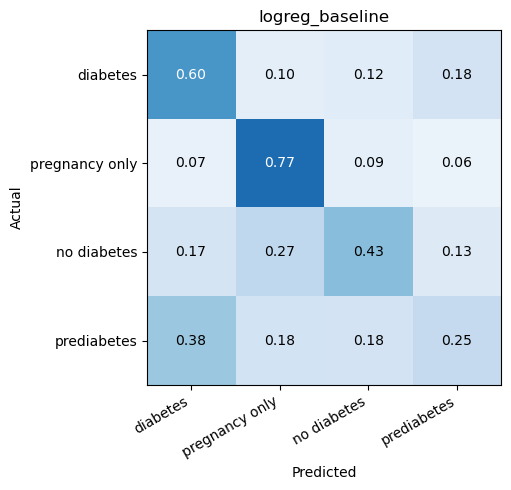

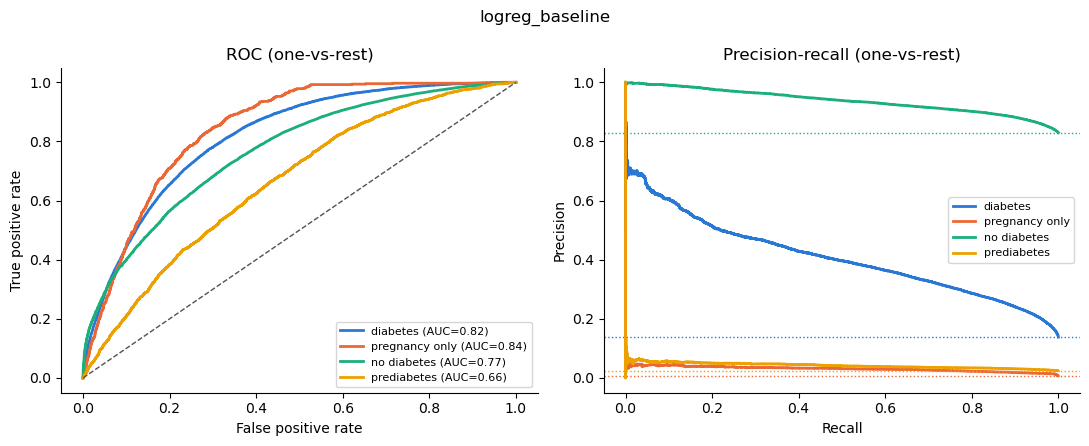

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[float64](4,)","[1.,2.,3.,4.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](28,)","['bmi','poor_physical_health_days','poor_mental_health_days',..., 'cant_afford_doctor','difficulty_walking','sex']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,28
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

In [48]:
baseline_pipeline = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        C=1.0,
        solver="lbfgs",
        random_state=RANDOM_STATE)),
])

config = {"model": "LogisticRegression", "class_weight": "balanced", "C": 1.0,
          "solver": "lbfgs", "max_iter": 1000, "ordinal_encoding": "onehot"}

log_experiment("logreg_baseline", baseline_pipeline, config,
               X_train, Y_train, X_val, Y_val, do_cv=True)


In [49]:
%load_ext tensorboard
%tensorboard --logdir runs


Launching TensorBoard...